In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

## Step 2: Download and load the dataset

In [2]:
# download the train and test files
os.makedirs("data", exist_ok=True)
url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
for f in ["KDDTrain+.txt", "KDDTest+.txt"]:
    if not os.path.exists("data/" + f):
        urllib.request.urlretrieve(url + f.replace("+", "%2B"), "data/" + f)

# the files have no header, so we give column names
columns = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment",
 "urgent","hot","num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root",
 "num_file_creations","num_shells","num_access_files","num_outbound_cmds","is_host_login","is_guest_login",
 "count","srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate",
 "diff_srv_rate","srv_diff_host_rate","dst_host_count","dst_host_srv_count","dst_host_same_srv_rate",
 "dst_host_diff_srv_rate","dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
 "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty"]

train = pd.read_csv("data/KDDTrain+.txt", names=columns)
test = pd.read_csv("data/KDDTest+.txt", names=columns)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
train.head()

Train shape: (125973, 43)
Test shape: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## Step 3: Look at the data

In [3]:
# make a simple target: 0 = normal, 1 = attack
train["target"] = (train["label"] != "normal").astype(int)
test["target"] = (test["label"] != "normal").astype(int)

print("Missing values:", train.isnull().sum().sum())
print()
print("Normal vs Attack in training data:")
print(train["target"].value_counts())

Missing values: 0

Normal vs Attack in training data:
target
0    67343
1    58630
Name: count, dtype: int64


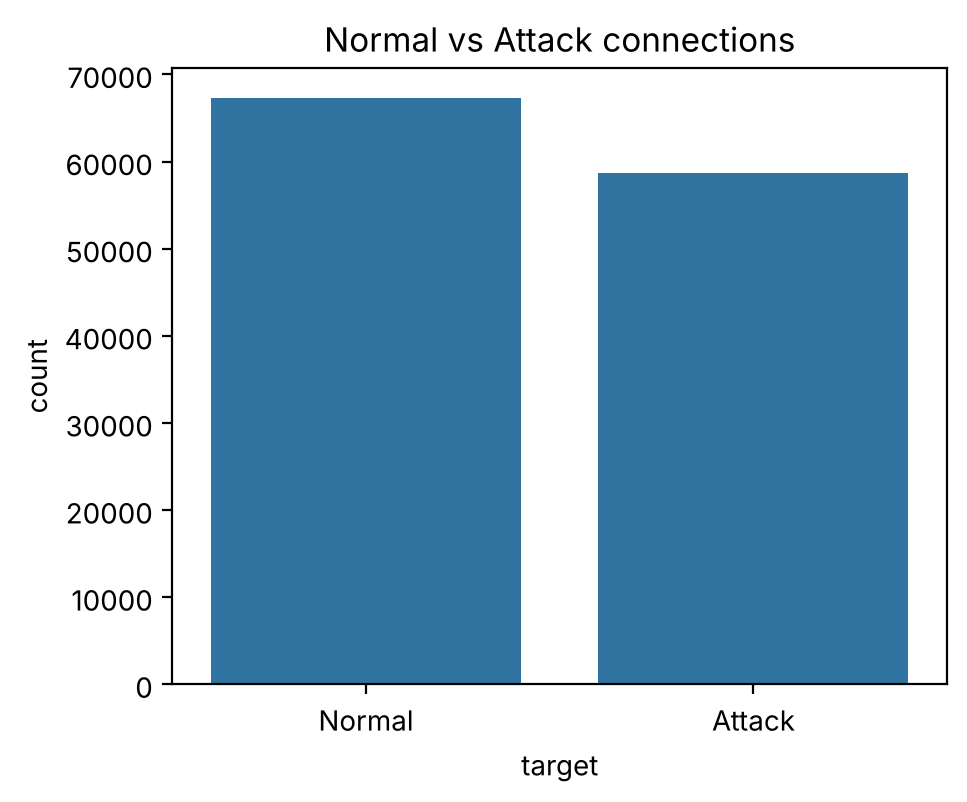

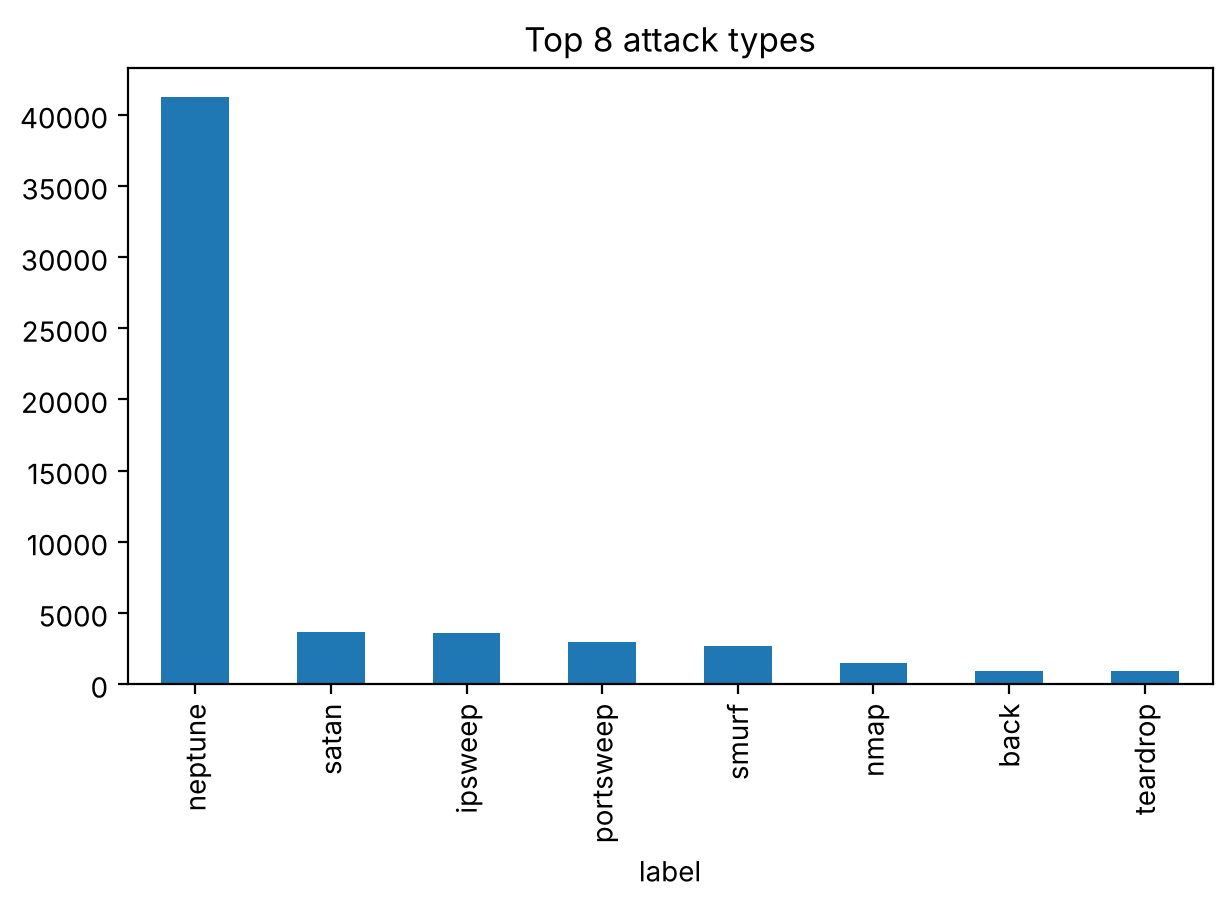

In [4]:
# bar chart of normal vs attack
plt.figure(figsize=(5, 4))
sns.countplot(x="target", data=train)
plt.xticks([0, 1], ["Normal", "Attack"])
plt.title("Normal vs Attack connections")
plt.show()

# most common attack types
train[train["label"] != "normal"]["label"].value_counts().head(8).plot(kind="bar", figsize=(7, 4), title="Top 8 attack types")
plt.show()

## Step 4: Data preprocessing

In [5]:
# 3 columns are text (protocol_type, service, flag) -> convert to numbers using one-hot encoding
both = pd.concat([train, test])
both = pd.get_dummies(both, columns=["protocol_type", "service", "flag"], dtype=int)

# split back into train and test
train_enc = both.iloc[:len(train)]
test_enc = both.iloc[len(train):]

# separate features (X) and target (y)
X_train = train_enc.drop(["label", "difficulty", "target"], axis=1)
y_train = train_enc["target"]
X_test = test_enc.drop(["label", "difficulty", "target"], axis=1)
y_test = test_enc["target"]

# scaling is needed for KNN and K-Means (they use distance)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Number of features:", X_train.shape[1])

Number of features: 122


## Step 5: Train the models

A small function is used to print the results of every model in the same way.

In [6]:
results = []   # to store the result of each model

def evaluate(name, y_pred):
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    results.append([name, acc, prec, rec, f1])
    print(name)
    print("Accuracy :", round(acc, 4))
    print("Precision:", round(prec, 4))
    print("Recall   :", round(rec, 4))
    print("F1 score :", round(f1, 4))
    print()

### 1. K-Nearest Neighbors (KNN)
KNN checks the 5 most similar connections in the training data and picks the majority class.

In [7]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)
evaluate("KNN", knn_pred)

KNN
Accuracy : 0.7704
Precision: 0.9234
Recall   : 0.6507
F1 score : 0.7635



### 2. Decision Tree
A decision tree asks a series of yes/no questions on the features to reach a decision.

In [8]:
dt = DecisionTreeClassifier(max_depth=10, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
evaluate("Decision Tree", dt_pred)

Decision Tree
Accuracy : 0.7861
Precision: 0.9677
Recall   : 0.6458
F1 score : 0.7747



### 3. Random Forest
Random Forest builds many decision trees and combines their votes.

In [9]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
evaluate("Random Forest", rf_pred)

Random Forest
Accuracy : 0.765
Precision: 0.967
Recall   : 0.608
F1 score : 0.7466



### 4. XGBoost
XGBoost builds trees one after another, and each new tree tries to fix the mistakes of the previous ones.

In [10]:
xgb = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42)
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)
evaluate("XGBoost", xgb_pred)

XGBoost
Accuracy : 0.7918
Precision: 0.9682
Recall   : 0.6557
F1 score : 0.7819



### 5. K-Means Clustering (unsupervised)
K-Means does **not** use the labels while training. It groups the connections into 2 clusters.
After that, we check which cluster mostly contains attacks and treat that as the "attack" cluster.

In [11]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X_train_scaled)

# find which cluster number means "attack" using the training data
train_clusters = kmeans.labels_
attack_cluster = 1 if y_train[train_clusters == 1].mean() > y_train[train_clusters == 0].mean() else 0
print("Cluster treated as attack:", attack_cluster)

# predict on test data
test_clusters = kmeans.predict(X_test_scaled)
kmeans_pred = (test_clusters == attack_cluster).astype(int)
evaluate("K-Means", kmeans_pred)

Cluster treated as attack: 0
K-Means
Accuracy : 0.5724
Precision: 0.5846
Recall   : 0.86
F1 score : 0.696



## Step 6: Compare all models

In [12]:
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
results_df = results_df.round(4)
results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.7704,0.9234,0.6507,0.7635
1,Decision Tree,0.7861,0.9677,0.6458,0.7747
2,Random Forest,0.7650,0.9670,0.6080,0.7466
3,XGBoost,0.7918,0.9682,0.6557,0.7819
4,K-Means,0.5724,0.5846,0.8600,0.6960


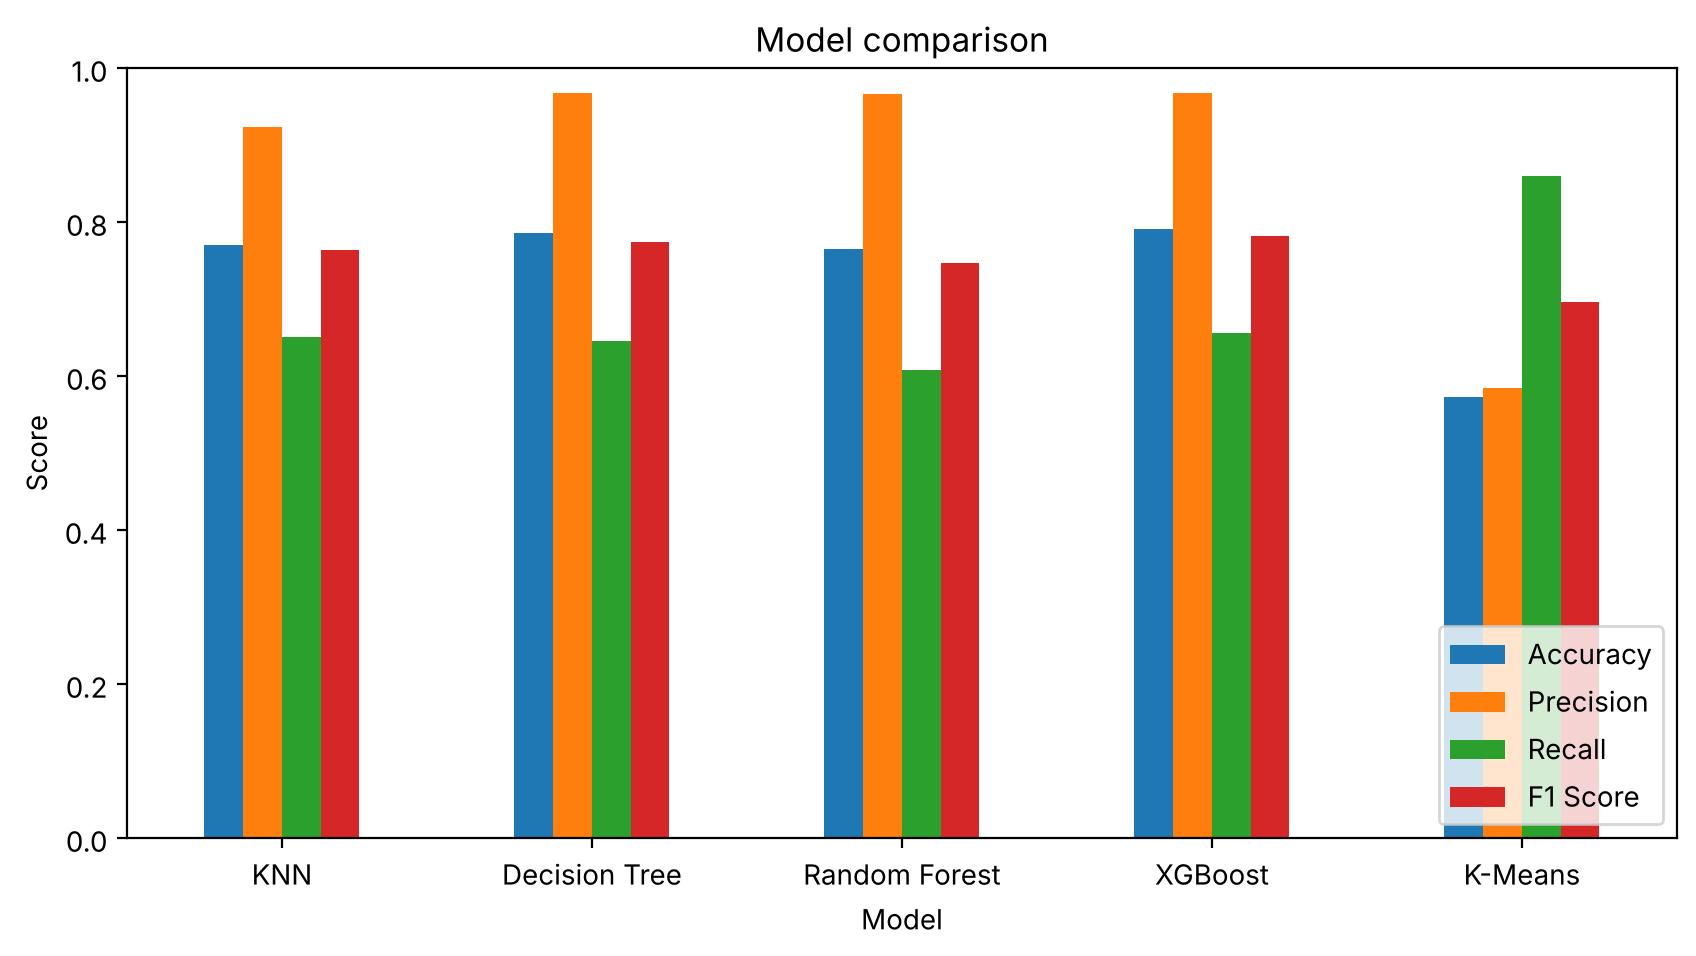

In [13]:
# bar chart comparing the models
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(kind="bar", figsize=(10, 5))
plt.title("Model comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

## Step 7: Confusion matrices

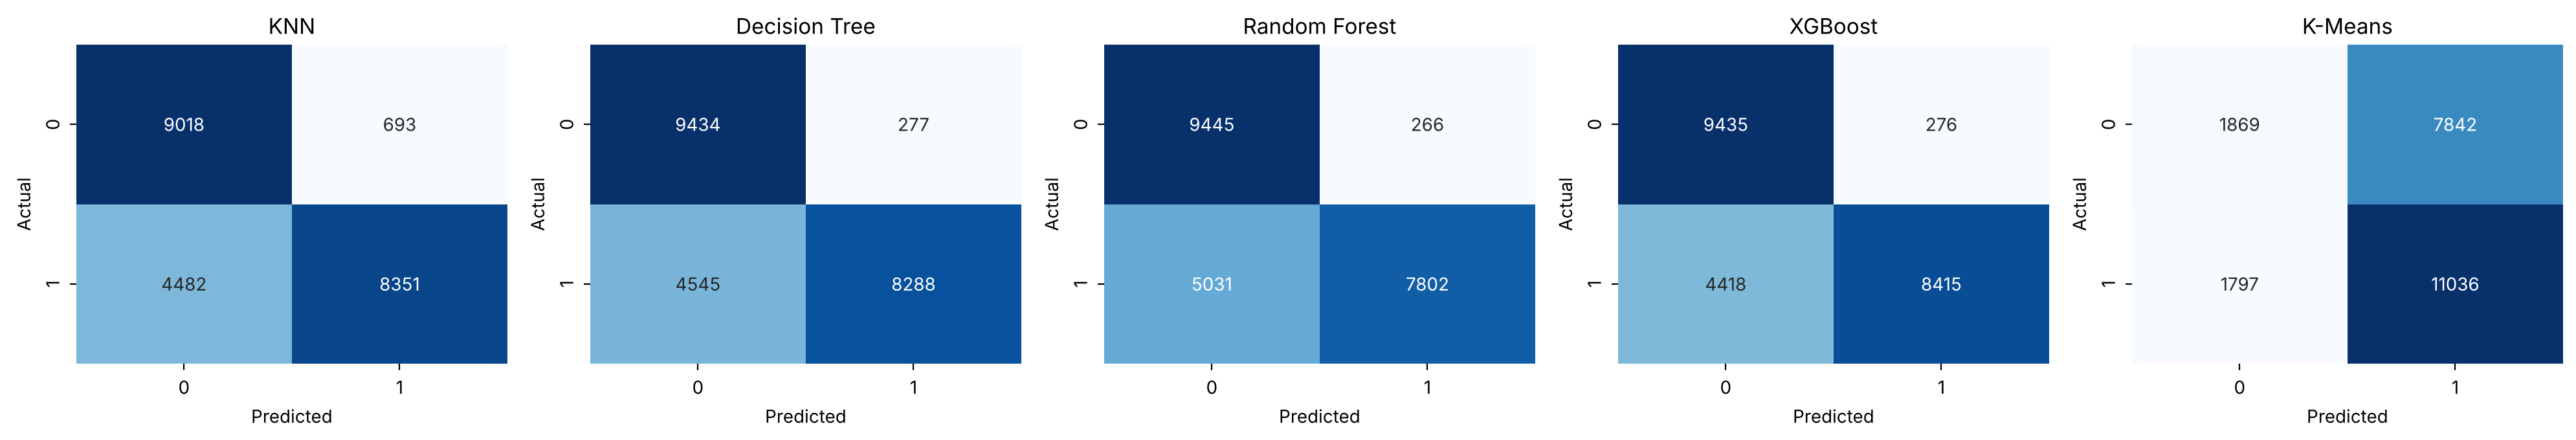

In [14]:
preds = {"KNN": knn_pred, "Decision Tree": dt_pred, "Random Forest": rf_pred,
         "XGBoost": xgb_pred, "K-Means": kmeans_pred}

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, (name, pred) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## Step 8: Important features

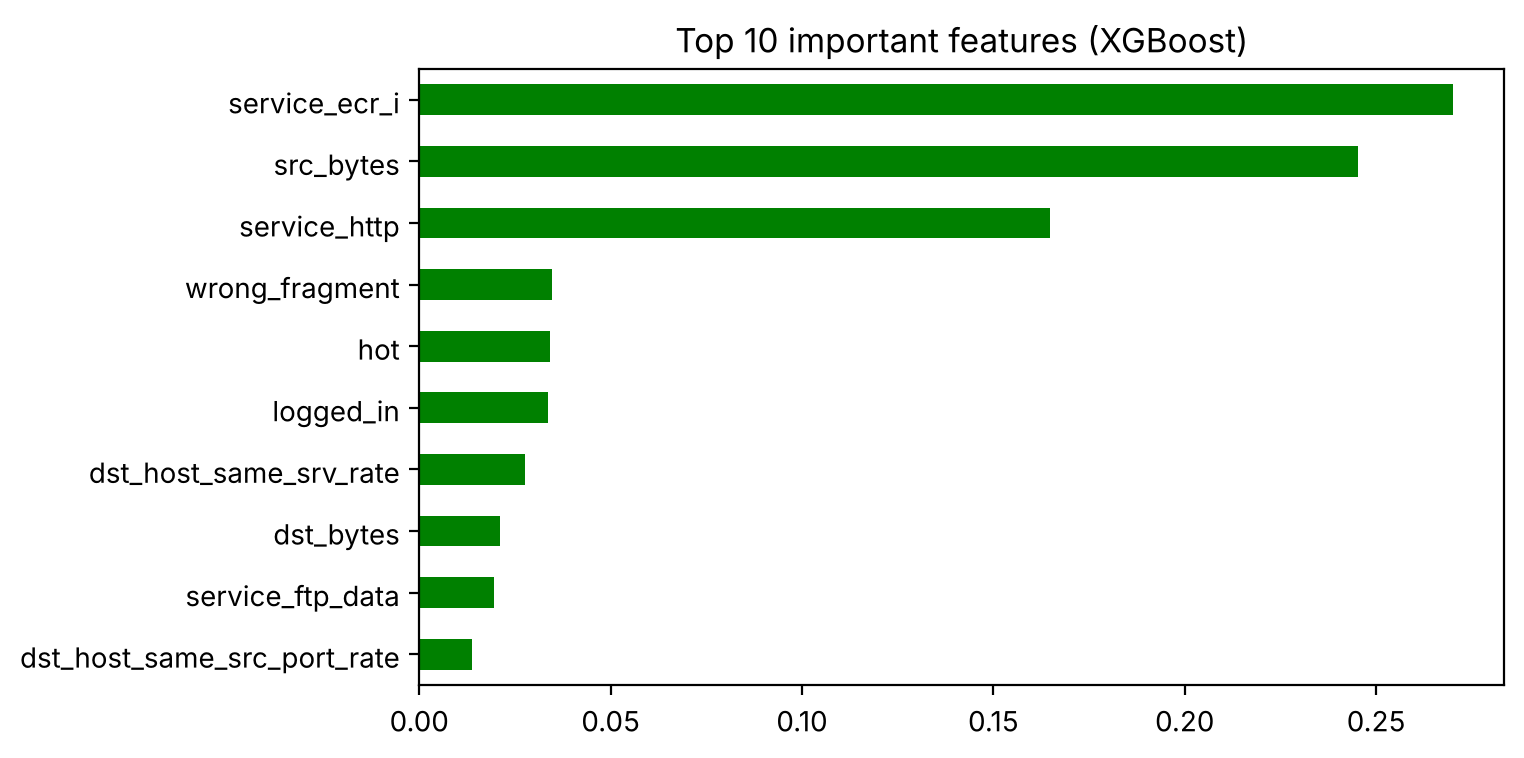

In [15]:
# top 10 features according to XGBoost
imp = pd.Series(xgb.feature_importances_, index=X_train.columns)
imp.nlargest(10).plot(kind="barh", figsize=(7, 4), color="green")
plt.title("Top 10 important features (XGBoost)")
plt.gca().invert_yaxis()
plt.show()

## Step 9: Conclusion

- Five algorithms were used to detect network intrusions: **KNN, Decision Tree, Random Forest, XGBoost and K-Means**.
- The tree-based models (Decision Tree, Random Forest, XGBoost) gave the best results with high precision.
- **K-Means** is unsupervised so it does not use labels, which is why its accuracy is lower than the supervised models.
- **KNN** works well but is slow on large data because it compares every test point with the training data.
- The test accuracy is lower than what we normally see on random splits because the NSL-KDD **test set contains new attack types that are not in the training set**.
- Recall is lower than precision, which means some attacks are missed. This can be improved in future.

**Future work:** tune hyperparameters, handle rare attack types (R2L, U2R) using SMOTE, try deep learning models, and build a real-time dashboard.